Original Dataset:
   order_value  distance_km  delivery_time_mins    rating  discount_pct
0   153.415803    15.287118           29.436359  1.610398     17.079069
1   645.943155     2.171641           41.143419  1.247733      4.256927
2   406.886462    15.151650           20.002291  3.285994     18.347489
3   606.425624    18.979243           18.019293  1.749068     29.233717
4   784.592658    12.467631           24.767687  3.171931      8.202608

Missing Values Before Cleaning:
order_value            0
distance_km            0
delivery_time_mins    10
rating                10
discount_pct           0
dtype: int64

Missing Values After Cleaning:
order_value           0
distance_km           0
delivery_time_mins    0
rating                0
discount_pct          0
dtype: int64

Dataset After Cleaning and Feature Engineering:
   order_value  distance_km  delivery_time_mins    rating  discount_pct  \
0   153.415803    15.287118           29.436359  1.610398     17.079069   
1   645.943155 

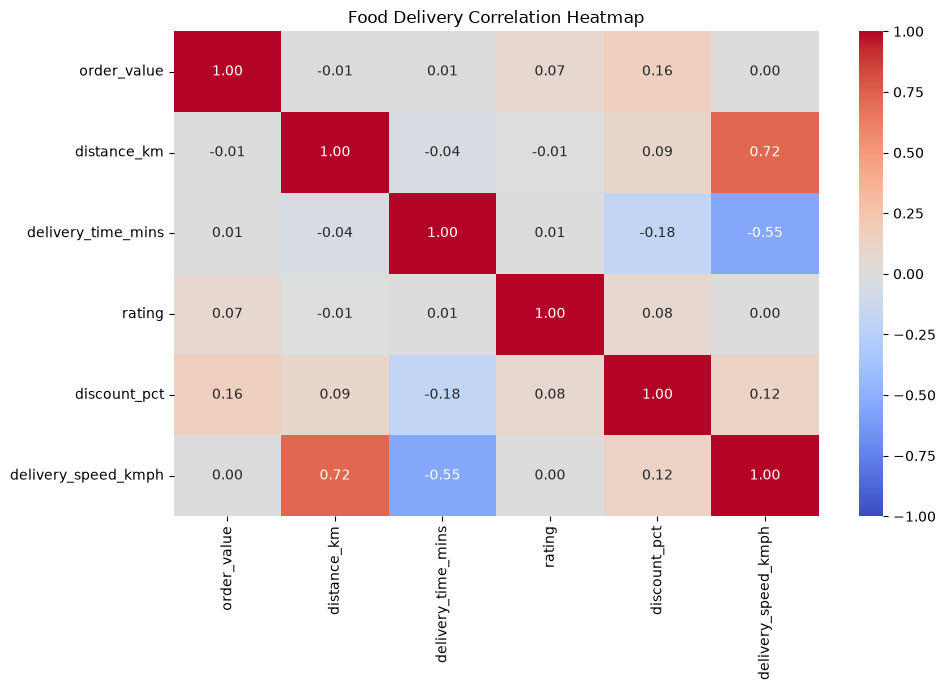

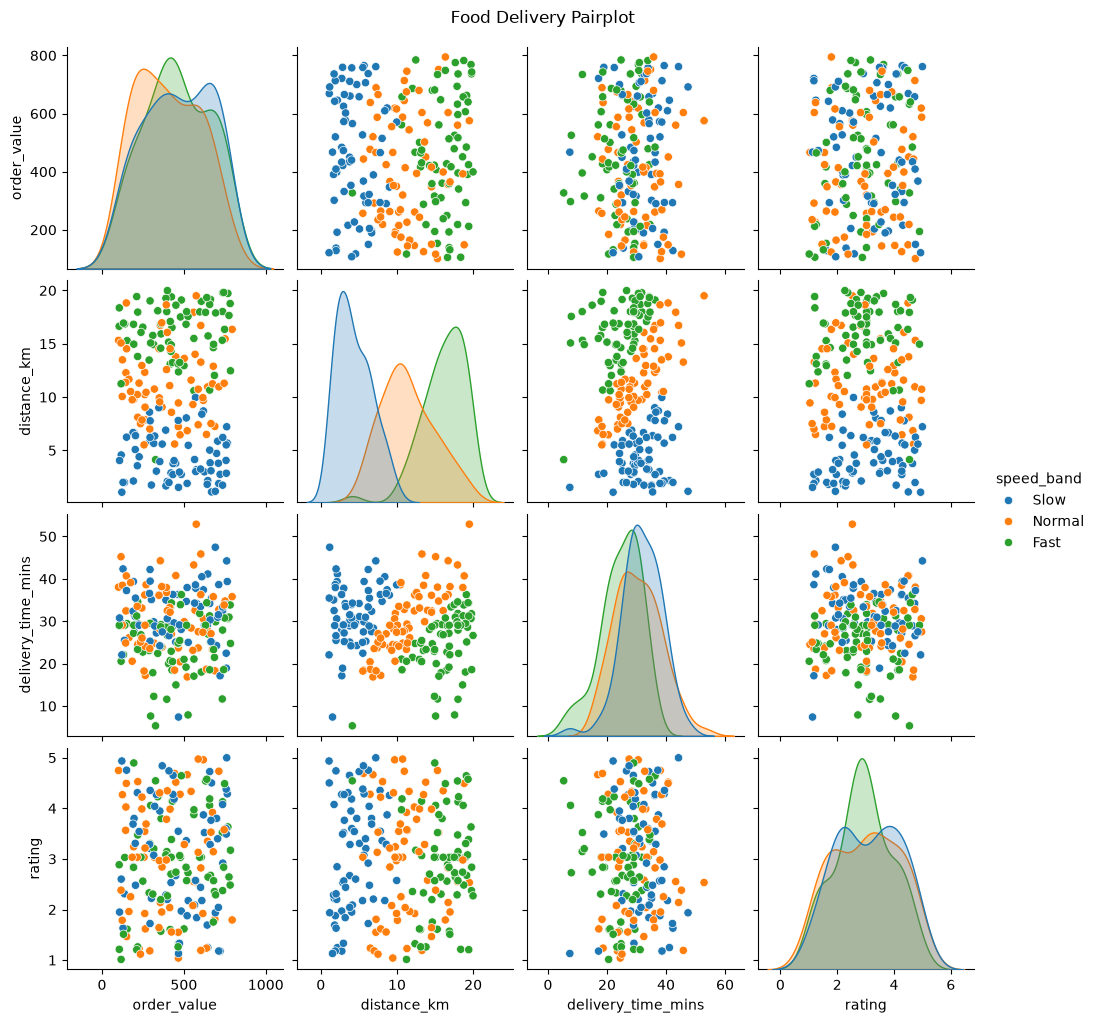


EDA Summary
Total Rows: 200
Total Columns: 7

Speed Band Counts:
speed_band
Slow      67
Fast      67
Normal    66
Name: count, dtype: int64

EDA Pipeline Completed Successfully!
Saved: correlation_heatmap.png
Saved: pairplot.png


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(7)

n = 200

data = {
    "order_value": np.random.uniform(100, 800, n),
    "distance_km": np.random.uniform(1, 20, n),
    "delivery_time_mins": np.random.normal(30, 8, n),
    "rating": np.random.uniform(1.0, 5.0, n),
    "discount_pct": np.random.uniform(0, 30, n)
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df.head())

null_count = int(n * 0.05)

delivery_null_indices = np.random.choice(
    df.index,
    size=null_count,
    replace=False
)

rating_null_indices = np.random.choice(
    df.index,
    size=null_count,
    replace=False
)

df.loc[delivery_null_indices, "delivery_time_mins"] = np.nan
df.loc[rating_null_indices, "rating"] = np.nan

print("\nMissing Values Before Cleaning:")
print(df.isnull().sum())

df["delivery_time_mins"] = df["delivery_time_mins"].fillna(
    df["delivery_time_mins"].median()
)

df["rating"] = df["rating"].fillna(
    df["rating"].median()
)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

df["delivery_speed_kmph"] = (
    df["distance_km"] /
    (df["delivery_time_mins"] / 60)
)

df["speed_band"] = pd.qcut(
    df["delivery_speed_kmph"],
    q=3,
    labels=["Slow", "Normal", "Fast"]
)

print("\nDataset After Cleaning and Feature Engineering:")
print(df.head())

correlation_matrix = df.select_dtypes(
    include="number"
).corr(method="pearson")

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Food Delivery Correlation Heatmap")
plt.tight_layout()

plt.savefig(
    "correlation_heatmap.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

pairplot = sns.pairplot(
    df[
        [
            "order_value",
            "distance_km",
            "delivery_time_mins",
            "rating",
            "speed_band"
        ]
    ],
    hue="speed_band"
)

pairplot.figure.suptitle(
    "Food Delivery Pairplot",
    y=1.02
)

pairplot.savefig(
    "pairplot.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\nEDA Summary")
print("Total Rows:", len(df))
print("Total Columns:", len(df.columns))
print("\nSpeed Band Counts:")
print(df["speed_band"].value_counts())

print("\nEDA Pipeline Completed Successfully!")
print("Saved: correlation_heatmap.png")
print("Saved: pairplot.png")